In [ ]:
# Block 1: Ich baue mir einen Korpus auf Sitzungsebene auf. 
# D.h. eine Zeile pro Plenarprotokoll (Sitzung), mit Metadaten und dem vollen Text. Das ist die Basis, auf der ich später die einzelnen Reden extrahiere
import xml.etree.ElementTree as ET
from pathlib import Path
import pandas as pd


data_folder = Path("xml")
all_files = sorted(data_folder.glob("*.xml"))
print(f"Ich habe {len(all_files)} XML-Dateien gefunden")


# Ich sammle die Ergebnisse zunächst in einer einfachen Python-Liste von Dictionaries

sessions = []


def get_tag_text(root, tag_name):
    # Ich suche das Element mit dem angegebenen Tag-Namen direkt unter dem Wurzelelement
    element = root.find(tag_name)
    if element is not None and element.text is not None:
        return element.text.strip()
    else:
        return None
    
# Ich gehe jetzt jede einzelne Datei durch
for file_path in all_files:
    tree = ET.parse(file_path)
    root = tree.getroot()

    session_id = get_tag_text(root, "id")
    session_date = get_tag_text(root, "datum")
    document_number = get_tag_text(root, "dokumentnummer")
    election_period = get_tag_text(root, "wahlperiode")
    full_text = get_tag_text(root, "text")

    sessions.append({
        "file_name": file_path.name,
        "session_id": session_id,
        "date": session_date,
        "document_number": document_number,
        "election_period": election_period,
        "full_text": full_text,
    })

sessions_df = pd.DataFrame(sessions)
sessions_df["date"] = pd.to_datetime(sessions_df["date"])
# sample(20) = random 20 Beispieldateien 
print(f"\nCorpus enthält {len(sessions_df)} Sitzungen")
print(f"Zeitraum: {sessions_df['date'].min()} bis {sessions_df['date'].max()}")
print(sessions_df[["file_name", "date", "document_number" , "election_period", "session_id"]].sample(20))

Ich habe 247 XML-Dateien gefunden

Corpus enthält 247 Sitzungen
Zeitraum: 2022-02-27 00:00:00 bis 2025-12-19 00:00:00
      file_name       date document_number election_period session_id
4    20_104.xml 2023-05-12          20/104              20       5571
103  20_201.xml 2024-11-15          20/201              20       5685
203   21_16.xml 2025-07-08           21/16              21       5721
140   20_44.xml 2022-06-23           20/44              20       5501
118   20_22.xml 2022-03-18           20/22              20       5474
69   20_169.xml 2024-05-16          20/169              20       5647
146   20_50.xml 2022-09-07           20/50              20       5508
57   20_157.xml 2024-03-14          20/157              20       5633
80   20_180.xml 2024-07-03          20/180              20       5660
174   20_78.xml 2023-01-18           20/78              20       5542
89   20_189.xml 2024-09-27          20/189              20       5672
72   20_172.xml 2024-06-06          20/172

In [ ]:
# Block 2: Ich zerlege den Fließtext jeder Sitzung in einzelne Reden. Da es dafür keine Tags gibt, erkenne ich Redner-Wechsel über ein Text-Muster (regex) 
# und filtere danach gezielt die falschen Treffer heraus (Tagesordnungspunkte usw.)

import re

# Muster für eine Redner-Ankündigungszeile, z.B. "Friedrich Merz (CDU/CSU):" oder "Olaf Scholz, Bundeskanzler:" oder "Präsidentin Bärbel Bas:".
# "^(?!\()" schließt Zwischenrufe wie "(Beifall bei der SPD)" aus, die auch in eigenen Zeilen stehen

# (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
speaker_pattern = re.compile(
    r"^(?!\()([A-ZÄÖÜ][^\n:()\d]{2,80}?)(?:,\s*([^\n:()]{2,80}?))?(?:\s*\(([^)]+)\))?:\s*$",
    re.MULTILINE
)
# Gruppe 1: Name 
# Gruppe 2: optionale Rolle nach Komma 
# Gruppe 3: optionale Fraktion in Klammern 
# Wichtig: "\d" ist jetzt im Namen ausgeschlossen - das entfernt automatisch Treffer wie "Tagesordnungspunkt 6" oder "Zusatzpunkt 3", die eine Zahl enthalten

# Zusätzlich brauche ich eine Blockliste für Fälle ohne Zahl, die trotzdem keine echten Redner sind (z.B. "Inhalt", "Nächste Sitzung"). Ich vergleiche in Kleinschreibung,
# damit ich Groß/Kleinschreibungsvarianten nicht einzeln auflisten muss

# (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
non_speaker_starts = (
    "inhalt", "nächste sitzung", "anlage", "namentliche abstimmung",
    "tagesordnungspunkt", "zusatzpunkt", "ergebnis", "schlussabstimmung"
)

def split_session_into_speeches(full_text, session_id, session_date, document_number):
    matches = list(speaker_pattern.finditer(full_text))
    speeches = []

# Ich benutze enumerate(), weil ich den Index jedes Treffers brauche (nicht nur den Treffer selbst). Der Index hilft mir später, den nächsten Treffer (matches[i + 1]) zu finden, um das Ende der aktuellen Rede zu bestimmen
        
    for i, match in enumerate(matches):
        speaker_name = match.group(1).strip()
        role_text = match.group(2).strip() if match.group(2) else None
        fraction_text = match.group(3).strip() if match.group(3) else None

        # Ich filtere hier alle Treffer heraus, die keine echten Redner sind, sondern strukturelle Überschriften des Protokolls
        
        if speaker_name.lower().startswith(non_speaker_starts):
            continue

        start_position = match.end()
        end_position = matches[i + 1].start() if i + 1 < len(matches) else len(full_text)
        speech_text = full_text[start_position:end_position].strip()

        # Ich verwerfe sehr kurze "Reden" (< 100 Zeichen) 
        
        if len(speech_text) < 100:
            continue

        speeches.append({
            "session_id": session_id,
            "date": session_date,
            "document_number": document_number,
            "speaker_name": speaker_name,
            "role_raw": role_text,
            "fraction_raw": fraction_text,
            "speech_text": speech_text,
            "speech_length": len(speech_text),
        })
    return speeches

# Ich wende die Funktion jetzt auf alle Sitzungen an und sammle alles in einer Liste, genau wie bei den Sitzungen selbs 

all_speeches = []
# Ich gehe jede Zeile (jede Sitzung) im DataFrame einzln durch. Der Unterstrich steht für den Index der Zeile, den ich hier nicht brauche, row enthält die Daten
for _, row in sessions_df.iterrows():
    if not row["full_text"]:
        continue
    all_speeches.extend(
        split_session_into_speeches(row["full_text"], row["session_id"], row["date"], row["document_number"])
    )
# Ich zerlege den Volltext der Sitzung in einzelne Reden (mit meiner eigenen Funktion) und übergebe dabei zusätzliche Infos (session_id, date, document_number), die jeder Rede zugeordnet werden sollen
# extend() statt append(), weil die Funktion eine Liste mehrerer Reden zurückgibt, die ich alle einzeln zu all_speeches hinzufügen will. append würde die ganze Liste als ein einzelnes Element anhängen\
    
    
speeches_df = pd.DataFrame(all_speeches)
print(f"Ich habe insgesamt {len(speeches_df)} Reden über alle 247 Sitzungen gefunden.")
print(f"Davon ohne erkannte Fraktion (z.B. Regierungsmitglieder/Präsidium): {speeches_df['fraction_raw'].isna().sum()}")
print("\nBeispiel-Reden:")
for speech in all_speeches[:10]:
    preview = speech["speech_text"][:60].replace("\n", " ")
    print(f"{speech['speaker_name']} | Rolle: {speech['role_raw']} | Fraktion: {speech['fraction_raw']} | '{preview}...'")

Ich habe insgesamt 69202 Reden über alle 247 Sitzungen gefunden.
Davon ohne erkannte Fraktion (z.B. Regierungsmitglieder/Präsidium): 31323

Beispiel-Reden:
Präsidentin Bärbel Bas | Rolle: None | Fraktion: None | 'Sehr geehrte Damen und Herren! Liebe Kolleginnen und Kollege...'
Nancy Faeser | Rolle: Bundesministerin des Innern und für Heimat | Fraktion: None | 'Sehr geehrte Frau Präsidentin! Meine Damen und Herren Abgeor...'
Alexander Throm | Rolle: None | Fraktion: CDU/CSU | 'Sehr geehrte Frau Präsidentin! Werte Kolleginnen und Kollege...'
Präsidentin Bärbel Bas | Rolle: None | Fraktion: None | 'Nächste Rednerin: für die Fraktion Bündnis 90/Die Grünen Kat...'
Katharina Dröge | Rolle: None | Fraktion: BÜNDNIS 90/DIE GRÜNEN | 'Sehr geehrte Frau Präsidentin! Liebe Kolleginnen und Kollege...'
Präsidentin Bärbel Bas | Rolle: None | Fraktion: None | 'Nächste Rednerin: für die Fraktion der AfD Gerrit Huy. (Beif...'
Gerrit Huy | Rolle: None | Fraktion: AfD | 'Frau Präsidentin! Werte Kollegen! 

In [ ]:
# Block 3: Ich fasse hier den gesamten Bereinigungsschritt zusammen:
# 1) Präsidium (neutrale Rolle) entfernen
# 2) Regierungsmitgliedern ihre Partei zuordnen
# 3) Fraktionsnamen normalisieren
# 4) alles verwerfen, was keiner der echten Fraktionen/Parteien entspricht


# 1) Minister-Wörterbuch: Name -> Partei 
# Deckt beide Kabinette im Untersuchungszeitraum ab (Scholz bis Mai 2025, Merz danach)

minister_party = {
    "Olaf Scholz": "SPD", "Christine Lambrecht": "SPD", "Boris Pistorius": "SPD",
    "Annalena Baerbock": "BÜNDNIS 90/DIE GRÜNEN", "Nancy Faeser": "SPD",
    "Christian Lindner": "FDP", "Jörg Kukies": "SPD",
    "Robert Habeck": "BÜNDNIS 90/DIE GRÜNEN", "Marco Buschmann": "FDP",
    "Hubertus Heil": "SPD", "Klara Geywitz": "SPD", "Karl Lauterbach": "SPD",
    "Volker Wissing": "FDP", "Cem Özdemir": "BÜNDNIS 90/DIE GRÜNEN",
    "Bettina Stark-Watzinger": "FDP", "Svenja Schulze": "SPD",
    "Steffi Lemke": "BÜNDNIS 90/DIE GRÜNEN",
    "Friedrich Merz": "CDU/CSU", "Lars Klingbeil": "SPD",
    "Alexander Dobrindt": "CDU/CSU", "Johann Wadephul": "CDU/CSU",
    "Stefanie Hubig": "SPD", "Bärbel Bas": "SPD", "Katherina Reiche": "CDU/CSU",
    "Verena Hubertz": "SPD", "Patrick Schnieder": "CDU/CSU",
    "Carsten Schneider": "SPD", "Nina Warken": "CDU/CSU", "Karin Prien": "CDU/CSU",
    "Dorothee Bär": "CDU/CSU", "Reem Alabali-Radovan": "SPD", "Alois Rainer": "CDU/CSU",
}

# Präsidium agiert in neutraler Rolle, also nicht als Parteivertreter
# (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
def is_presidium_speaker(speaker_name):
    return bool(re.match(r"^(Präsident|Vizepräsident)", speaker_name))

# Wenn schon eine Fraktion direkt aus den Klammern im Text erkannt wurde (z.B. CDU/CSU), behalte ich genau diesen Wert. Andernfalls handelt es sich vermutlich um ein Regierungsmitglied (Kanzler/Minister),
# das im Text keine Fraktion in Klammern hat, sondern nur eine Amtsbezeichnung

def assign_fraction(row):
    if row["fraction_raw"]:
        return row["fraction_raw"]
    return minister_party.get(row["speaker_name"])


def normalize_fraction(raw_value):
    if pd.isna(raw_value) or not isinstance(raw_value, str):
        return None
    
    # Zeilenumbrüche/Mehrfach Leerzeichen mitten im Namen vereinheitlichen
    # (z.B. "DIE\nLINKE" - "DIE LINKE"), dann in Kleinschreibung vergleichen
    # (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
    cleaned_lower = re.sub(r"\s+", " ", raw_value).strip().lower()

    if "cdu" in cleaned_lower or "csu" in cleaned_lower:
        return "CDU/CSU"
    if cleaned_lower == "spd":
        return "SPD"
    if cleaned_lower == "afd":
        return "AfD"
    if "grün" in cleaned_lower or "bündnis 90" in cleaned_lower:
        return "BÜNDNIS 90/DIE GRÜNEN"
    if cleaned_lower == "fdp":
        return "FDP"
    if "linke" in cleaned_lower:
        return "DIE LINKE"
    if "bsw" in cleaned_lower or "wagenknecht" in cleaned_lower:
        return "BSW"
    if "fraktionslos" in cleaned_lower:
        return "fraktionslos"
    return None

# Ich wende jetzt alle drei Bereinigungsschritte in der richtigen Reihenfolge an und prüfe am Ende, wie viele Reden dabei übrig geblieben sind 
# Ich entferne alle Zeilen, bei denen der Redner zum Präsidium gehört (neutrale Rolle). Das ~ negiert die Bedingung, ich behalte alles, wo is_presidium_speaker nicht True ist

speeches_df = speeches_df[~speeches_df["speaker_name"].apply(is_presidium_speaker)].copy()

# Ich ordne jeder Rede eine Partei zu. Entweder aus dem Text selbst oder über mein Minister-Wörterbuch. axis=1 bedeutet, 
# dass die Funktion bekommt jeweils eine ganze Zeile (row) übergeben, nicht nur eine einzelne Spalte
speeches_df["fraction"] = speeches_df.apply(assign_fraction, axis=1)
speeches_df["fraction"] = speeches_df["fraction"].apply(normalize_fraction)

before_count = len(speeches_df)
speeches_df = speeches_df.dropna(subset=["fraction"]).copy()
after_count = len(speeches_df)

print(f"Reden vor Bereinigung: {before_count}")
print(f"Reden nach vollständiger Bereinigung: {after_count}  (entfernt: {before_count - after_count})")

print("\nBereinigte Verteilung nach Fraktion:")
print(speeches_df["fraction"].value_counts())

# Ich prüfe zusätzlich die Längenverteilung, um Extraktionsfehler zu entdecken 
print("\nStatistik der Redelängen (Zeichen):")
print(speeches_df["speech_length"].describe())

Reden vor Bereinigung: 48542
Reden nach vollständiger Bereinigung: 37784  (entfernt: 10758)

Bereinigte Verteilung nach Fraktion:
fraction
CDU/CSU                  10266
SPD                       7142
AfD                       6345
BÜNDNIS 90/DIE GRÜNEN     6048
DIE LINKE                 3531
FDP                       3382
fraktionslos               799
BSW                        271
Name: count, dtype: int64

Statistik der Redelängen (Zeichen):
count    37784.000000
mean      2835.558729
std       2305.471945
min        100.000000
25%        615.750000
50%       2802.500000
75%       4490.000000
max      28008.000000
Name: speech_length, dtype: float64


In [ ]:
# Block 4: Ich entferne die Bühnenanweisungen (Beifall, Zurufe usw.) aus dem Redetext weil sie einfach nicht relevant für mich sind

# (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
stage_direction_pattern = re.compile(
    r"\((?:Beifall|Zuruf|Zurufe|Heiterkeit|Lachen|Widerspruch|Unruhe|Gegenruf"
    r"|Die Abgeordneten|Die Fraktionen|Lebhaft|Anhaltend|Langanhaltend)[^)]*\)",
    re.IGNORECASE
)

# Mehrfache Leerzeichen/Zeilenumbrüche, die durch das Entfernen entstehen, fasse ich zu einem einzelnen Leerzeichen zusammen

def clean_speech_text(speech_text):
    text_without_directions = stage_direction_pattern.sub(" ", speech_text)
    # (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
    return re.sub(r"\s+", " ", text_without_directions).strip()

speeches_df["clean_text"] = speeches_df["speech_text"].apply(clean_speech_text)

# Wortanzahl im bereinigten Text
# ich brauche das später, um Wehrdiensterwähnungen relativ zu berechnen, statt nur absolute Zahlen zu vergleichen, da die Fraktionen unterschiedlich viel und unterschiedlich oft reden

speeches_df["word_count"] = speeches_df["clean_text"].str.split().apply(len)

print(f"\nGesamtwortzahl im bereinigten Corpus: {speeches_df['word_count'].sum():,}")
print("\nWortzahl nach Fraktion (Summe):")
print(speeches_df.groupby("fraction")["word_count"].sum().sort_values(ascending=False))


Gesamtwortzahl im bereinigten Corpus: 14,103,712

Wortzahl nach Fraktion (Summe):
fraction
CDU/CSU                  3800990
SPD                      3325204
BÜNDNIS 90/DIE GRÜNEN    2203051
AfD                      2060851
FDP                      1479591
DIE LINKE                1029602
fraktionslos              148075
BSW                        56348
Name: word_count, dtype: int64


In [ ]:
# Block 5: Ich definiere eine Liste von Schlüsselwörtern rund um Wehrdienst und durchsuche damit jede Rede
# Ich nehme nicht nur Wehrdienst selbst, sondern auch die wichtigsten verwandten Begriffe, weil das Thema in der politischen Debatte unter verschiedenen Namen auftaucht 
# z.B. neuer Wehrdienst, Wehrpflicht, Dienstpflicht


# Ich benutze Wortstämme statt kompletter Wörter (z.B. wehrdienst statt Wehrdienst), weil ich damit automatisch auch Flexionsformen erfasse, also z.B. Wehrdienstes, Wehrdienstpflicht,
# usw. Das mache ich bewusst als Teilstring-Suche, nicht mit \b, weil zusammengesetzte Wörter sonst nicht erfasst würden


keyword_stems = [
    "wehrdienst",       
    "wehrpflicht",      
    "dienstpflicht",    
    "pflichtjahr",      
    "musterung",        
    "wehrertüchtigung",  
    "kriegsdienst",      
]

# Ich baue mir daraus ein einziges kombiniertes Regex-Muster mit "|" , case-insensitive, damit ich nicht für jedes Wort einzeln suchen muss
# (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
keyword_pattern = re.compile("|".join(keyword_stems), re.IGNORECASE)

def count_keyword(text):
    return len(keyword_pattern.findall(text))

speeches_df["keyword_hits"] = speeches_df["clean_text"].apply(count_keyword)
speeches_df["mentions_wehrdienst"] = speeches_df["keyword_hits"] > 0

relevant_speeches = speeches_df[speeches_df["mentions_wehrdienst"]].copy()


print(f"Reden mit mindestens einer Wehrdienst-Erwähnung: {len(relevant_speeches)} von {len(speeches_df)}")
print(f"Gesamtzahl aller Erwähnungen (Treffer summiert): {speeches_df['keyword_hits'].sum()}")

print("\nErwähnungen nach Fraktion (Anzahl Reden mit Treffer):")
print(relevant_speeches.groupby("fraction").size().sort_values(ascending=False))

print("\nErwähnungen nach Fraktion (Summe aller Treffer):")
print(relevant_speeches.groupby("fraction")["keyword_hits"].sum().sort_values(ascending=False))

# Ich schaue mir 5 BeispielReden mit den meisten Treffern an, um zu prüfen, ob die Suche wirklich funktioniert

top_examples = relevant_speeches.sort_values("keyword_hits", ascending=False).head(5)
for _, row in top_examples.iterrows():
    print(f"\n{row['date'].date()} | {row['speaker_name']} ({row['fraction']}) | Treffer: {row['keyword_hits']}")
    print(row["clean_text"][:222])

Reden mit mindestens einer Wehrdienst-Erwähnung: 298 von 37784
Gesamtzahl aller Erwähnungen (Treffer summiert): 660

Erwähnungen nach Fraktion (Anzahl Reden mit Treffer):
fraction
CDU/CSU                  91
AfD                      66
DIE LINKE                44
SPD                      40
BÜNDNIS 90/DIE GRÜNEN    37
FDP                      10
fraktionslos              8
BSW                       2
dtype: int64

Erwähnungen nach Fraktion (Summe aller Treffer):
fraction
CDU/CSU                  200
AfD                      169
DIE LINKE                 99
SPD                       81
BÜNDNIS 90/DIE GRÜNEN     79
FDP                       14
fraktionslos              10
BSW                        8
Name: keyword_hits, dtype: int64

2025-12-05 | Dr. Rainer Kraft (AfD) | Treffer: 17
Die Frage der Wehrpflicht ist im Kern eine Frage der Staatsbürgerschaft. Seit der Entstehung moderner Republiken gilt: Staatsbürgerschaft und Landesverteidigung sind zwei Seiten derselben Medaille. Wer die po

In [ ]:
# Block 6: Ich untersuche, wann im Untersuchungszeitraum (Feb. 2022 - Dez. 2025) über Wehrdienst gesprochen wurde. Das ist zentral für meine Fragestellung,
# weil ich prüfen will, ob sich die Debatte im Zeitverlauf verändert hat (z.B. Anstieg nach Kriegsbeginn, erneuter Anstieg bei der Wehrdienst-Reform 2025)

# Ich runde jedes Datum auf den jeweiligen Monat ab (Periode), um eine sinnvolle Zeiteinheit für die Aggregation zu haben. Pro Tag wäre zu kleinteilig, weil ja nicht an jedem Tag getagt wird

speeches_df["month"] = speeches_df["date"].dt.to_period("M")

# Ich aggregiere pro Monat: Gesamtzahl Reden, Gesamtwortzahl, und Anzahl/Summe der Treffer
# Das brauche ich, um die Erwähnungen relativ zur jeweiligen Debattenmenge zu betrachten 
# ein Monat mit vielen Sitzungen hat sonst automatisch auch mehr absolute Erwähnungen


monthly_stats = speeches_df.groupby("month").agg(
    total_speeches=("speech_length", "count"),
    total_words=("word_count", "sum"),
    keyword_hits=("keyword_hits", "sum"),
).reset_index()

# Erwähnungen pro 10.000 Wörter. Das macht verschiedene Monate vergleichbar, unabhängig davon, wie viel insgesamt in diesem Monat geredet wurde

monthly_stats["hits_per_10k_words"] = (
    monthly_stats["keyword_hits"] / monthly_stats["total_words"] * 10_000
)

# Ich markiere mir den Kriegsbeginn (24.02.2022) als Referenzpunkt
# freq="M" sagt pandas, dass es sich um eine Monatsperiode handelt, kein Tagesdatum

war_start = pd.Period("2022-02", freq="M")

def classify_phase(month):
    if month < war_start:
        return "vor Kriegsbeginn"
    else:
        return "nach Kriegsbeginn"
monthly_stats["phase"] = monthly_stats["month"].apply(classify_phase)


print("Monate mit den meisten Wehrdienst-Erwähnungen (relativ zur Wortzahl):")
print(monthly_stats.sort_values("hits_per_10k_words", ascending=False).head(10)
    [["month", "total_speeches", "keyword_hits", "hits_per_10k_words"]])

print("\nErste 5 Monate im Corpus (Kriegsbeginn-Phase):")
print(monthly_stats.head(5)[["month", "total_speeches", "keyword_hits", "hits_per_10k_words"]])


Monate mit den meisten Wehrdienst-Erwähnungen (relativ zur Wortzahl):
      month  total_speeches  keyword_hits  hits_per_10k_words
41  2025-12            1160           125            3.522446
39  2025-10            1048            74            2.349124
38  2025-09            1422           130            2.248524
0   2022-02              22             2            1.339316
40  2025-11            1610            66            1.188855
35  2025-05             817            22            0.809791
36  2025-06            1033            23            0.727961
37  2025-07             548            16            0.653296
24  2024-04            1111            21            0.545198
14  2023-05             972            17            0.465585

Erste 5 Monate im Corpus (Kriegsbeginn-Phase):
     month  total_speeches  keyword_hits  hits_per_10k_words
0  2022-02              22             2            1.339316
1  2022-03             899             2            0.051254
2  2022-04       

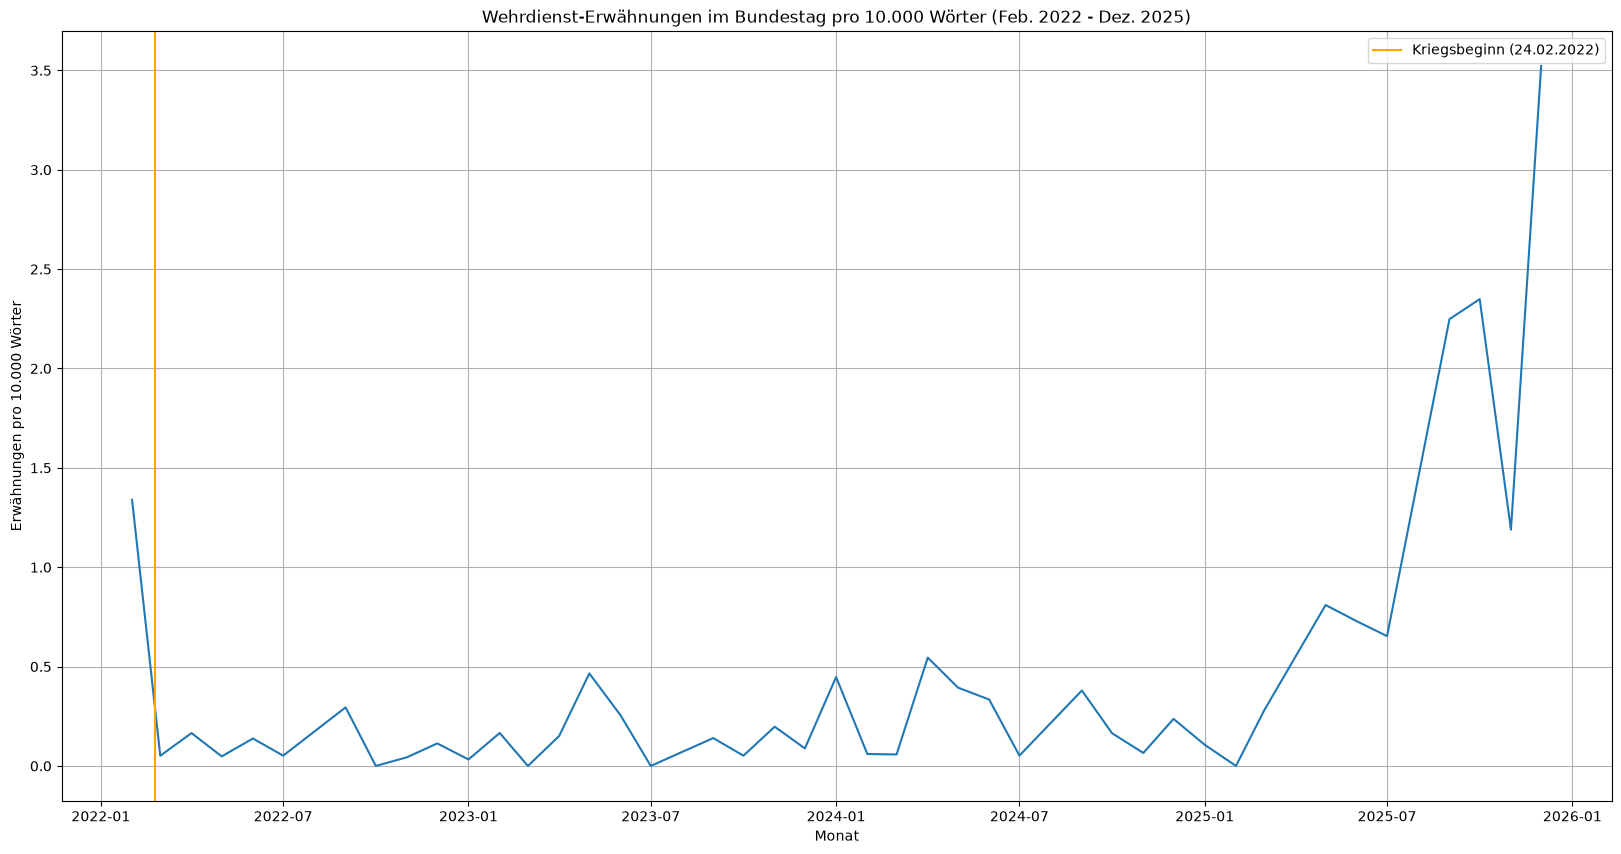

In [ ]:
# Block 7: Ich visualisiere den Zeitverlauf der Wehrdienst-Erwähnungen, um den Kontrast zwischen der kurzen 2022 Reaktion  und der konkreten Gesetzesdebatte 2025 sichtbar zu machen

# Ich wandle die Period-Spalte in ein echtes Datum um (Monatsanfang)
import matplotlib.pyplot as plt

monthly_stats["month_start"] = monthly_stats["month"].dt.to_timestamp()
war_start_date = pd.Timestamp("2022-02-24")

fig, ax = plt.subplots(figsize=(20, 10))
ax.plot(monthly_stats["month_start"], monthly_stats["hits_per_10k_words"])

# Ich markiere den Kriegsbeginn mit einer vertikalen Linie, weil das mein zentraler Referenzpunkt für die Fragestellung ist 

ax.axvline(war_start_date, color="orange", label="Kriegsbeginn (24.02.2022)")

ax.set_title("Wehrdienst-Erwähnungen im Bundestag pro 10.000 Wörter (Feb. 2022 - Dez. 2025)")
ax.set_xlabel("Monat")
ax.set_ylabel("Erwähnungen pro 10.000 Wörter")
ax.legend()
ax.grid()
plt.show()

# Wichtig: to_timestamp() setzt den Punkt immer auf den 1. Tag des Monats, nicht auf das tatsächliche Sitzungsdatum. Der Punkt für Februar 2022 steht deshalb links von
# der Kriegsbeginn-Linie (24.02.), obwohl die echte Sitzung erst am 27.02. stattfand. Das ist nur ein Darstellungsartefakt der Monats-Aggregation, kein Fehler in den Daten


In [ ]:
# Block 8: Ich baue mir ein Frame-Wörterbuch und schaue, welche Kategorien im unmittelbaren Kontext von Wehrdienst-Erwähnungen auftauchen

# Ich nehme bewusst ein Kontextfenster statt der ganzen Rede, weil eine Rede oft mehrere Themen behandelt. Mich interessiert nur, was direkt um das Stichwort herum steht

# Mein Frame-Wörterbuch sieht so aus: 

frame_dictionary = {
    "Sicherheit": [
        "sicherheit", "bedrohung", "verteidigung", "abschreckung", "angriff",
        "kriegstüchtig", "landesverteidigung", "bündnisfähig", "nato", "feind"
    ],
    "Personal": [
        "personal", "rekrutier", "nachwuchs", "reserve", "mangel", "fachkräfte",
        "truppenstärke", "soldat", "besetzung", "auffüll"
    ],
    "Freiheit": [
        "freiheit", "zwang", "selbstbestimmung", "freiwillig", "grundrecht",
        "gewissen", "autonomie", "verweigerung", "individuell"
    ],
    "Gerechtigkeit": [
        "gerecht", "gleichberechtigung", "frauen", "geschlecht", "lastenverteilung",
        "ungleich", "diskriminier", "generationengerecht", "fairness"
    ],
    "Gesellschaft": [
        "gesellschaft", "zusammenhalt", "integration", "ehrenamt", "engagement",
        "gemeinschaft", "sozialer dienst", "zivilgesellschaft", "verantwortung"
    ],
    "Praktikabilität": [
        "kaserne", "ausbilder", "kosten", "bürokrat", "infrastruktur", "haushalt",
        "umsetzung", "kapazität", "ausrüstung", "ausbildungsplätze", "finanzier"
    ],
}

# Ich baue mir aus jeder Kategorie ein kombiniertes Regex-Muster

# (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
frame_patterns = {
    category: re.compile("|".join(stems), re.IGNORECASE)
    for category, stems in frame_dictionary.items()
}

WINDOW_SIZE = 50  # Anzahl Wörter links und rechts vom Stichwort

def extract_context_windows(text, keyword_regex, window_size=WINDOW_SIZE):
    
# Ich zerlege den Text in Wörter, weil ich Wort-basierte (nicht Zeichen-basierte) Fenster brauche
# Diese Funktion sucht alle Stellen im Text, an denen ein Keyword vorkommt, und schneidet dort jeweils ein paar Wörter davor und danach aus (Kontextfenster)
# Am Ende werden alle diese Ausschnitte zu einem String zusammengefügt und zurückgegeben, statt den ganzen Text. So sieht man schnell, in welchem Zusammenhang das Keyword steht
    
    words = text.split()
    contexts = []
    for i, word in enumerate(words):
        if keyword_regex.search(word):
            start = max(0, i - window_size)
            end = min(len(words), i + window_size + 1)
            contexts.append(" ".join(words[start:end]))
    return " ".join(contexts)

# Ich wende das nur auf die bereits gefilterten Wehrdienst-Reden an (relevant_speeches), nicht auf den ganzen Corpus. Das spart Rechenzeit und ist inhaltlich auch korrekt


# apply() ruft für jede Zeile diese kleine, unbenannte Funktion (lambda) auf und übergibt ihr den Text aus der Spalte "clean_text" als "text". Die lambda ruft dann einfach meine
# vorhandene Funktion extract_context_windows() auf und reicht zusätzlich keyword_pattern mit, das apply() selbst nicht automatisch durchreichen würde
# (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
relevant_speeches["context_window"] = relevant_speeches["clean_text"].apply(
    lambda text: extract_context_windows(text, keyword_pattern)
)

# Für jede Kategorie zähle ich die Treffer im Kontextfenster jeder Rede

# Auch hier nimmt die lambda den Text aus "context_window" und zählt mit pattern.findall(), wie oft das Muster der aktuellen Kategorie (pattern) darin vorkommt
# (KI-Hilfe wurde verwendet, mehr dazu in meiner Projektdokumentation)
for category, pattern in frame_patterns.items():
    relevant_speeches[f"frame_{category}"] = relevant_speeches["context_window"].apply(
        lambda text: len(pattern.findall(text))
    )

# Dieser Code fasst zusammen, wie oft die verschiedenen Frames in den Wehrdienst-Reden insgesamt und pro Fraktion vorkommen
# Zuerst wird eine Liste aller Frame-Spalten erstellt (frame_columns), dann werden die Häufigkeiten über alle Reden hinweg summiert und absteigend sortiert ausgegeben
# so sieht man, welcher Frame am häufigsten verwendet wird. Danach werden die gleichen Summen zusätzlich pro Fraktion berechnet mit groupby("fraction"), sodass man vergleichen kann, welche Fraktion welche Frames wie oft nutzt

frame_columns = [f"frame_{c}" for c in frame_dictionary]
print("Frame-Häufigkeiten insgesamt (über alle Wehrdienst-Reden):")
print(relevant_speeches[frame_columns].sum().sort_values(ascending=False))

print("\nFrame-Häufigkeiten nach Fraktion (Summe):")
print(relevant_speeches.groupby("fraction")[frame_columns].sum())

Frame-Häufigkeiten insgesamt (über alle Wehrdienst-Reden):
frame_Freiheit           478
frame_Sicherheit         459
frame_Personal           331
frame_Gesellschaft       294
frame_Praktikabilität    116
frame_Gerechtigkeit       89
dtype: int64

Frame-Häufigkeiten nach Fraktion (Summe):
                       frame_Sicherheit  frame_Personal  frame_Freiheit  \
fraction                                                                  
AfD                                 147              52              69   
BSW                                   0               6              20   
BÜNDNIS 90/DIE GRÜNEN                48              43              90   
CDU/CSU                             162             129             114   
DIE LINKE                            31              36              86   
FDP                                   3              11               9   
SPD                                  58              50              77   
fraktionslos                        

Frame-Profil pro Fraktion (in % der Frame-Erwähnungen dieser Fraktion):
                       Sicherheit  Personal  Freiheit  Gerechtigkeit  \
fraction                                                               
CDU/CSU                      28.6      22.8      20.1            1.8   
AfD                          39.5      14.0      18.5           11.3   
DIE LINKE                    13.3      15.5      36.9            8.6   
SPD                          24.5      21.1      32.5            1.3   
BÜNDNIS 90/DIE GRÜNEN        19.1      17.1      35.9            4.4   
FDP                           6.5      23.9      19.6            6.5   
fraktionslos                 27.8      11.1      36.1            0.0   
BSW                           0.0      23.1      76.9            0.0   

                       Gesellschaft  Praktikabilität  
fraction                                              
CDU/CSU                        22.1              4.6  
AfD                             9.7       

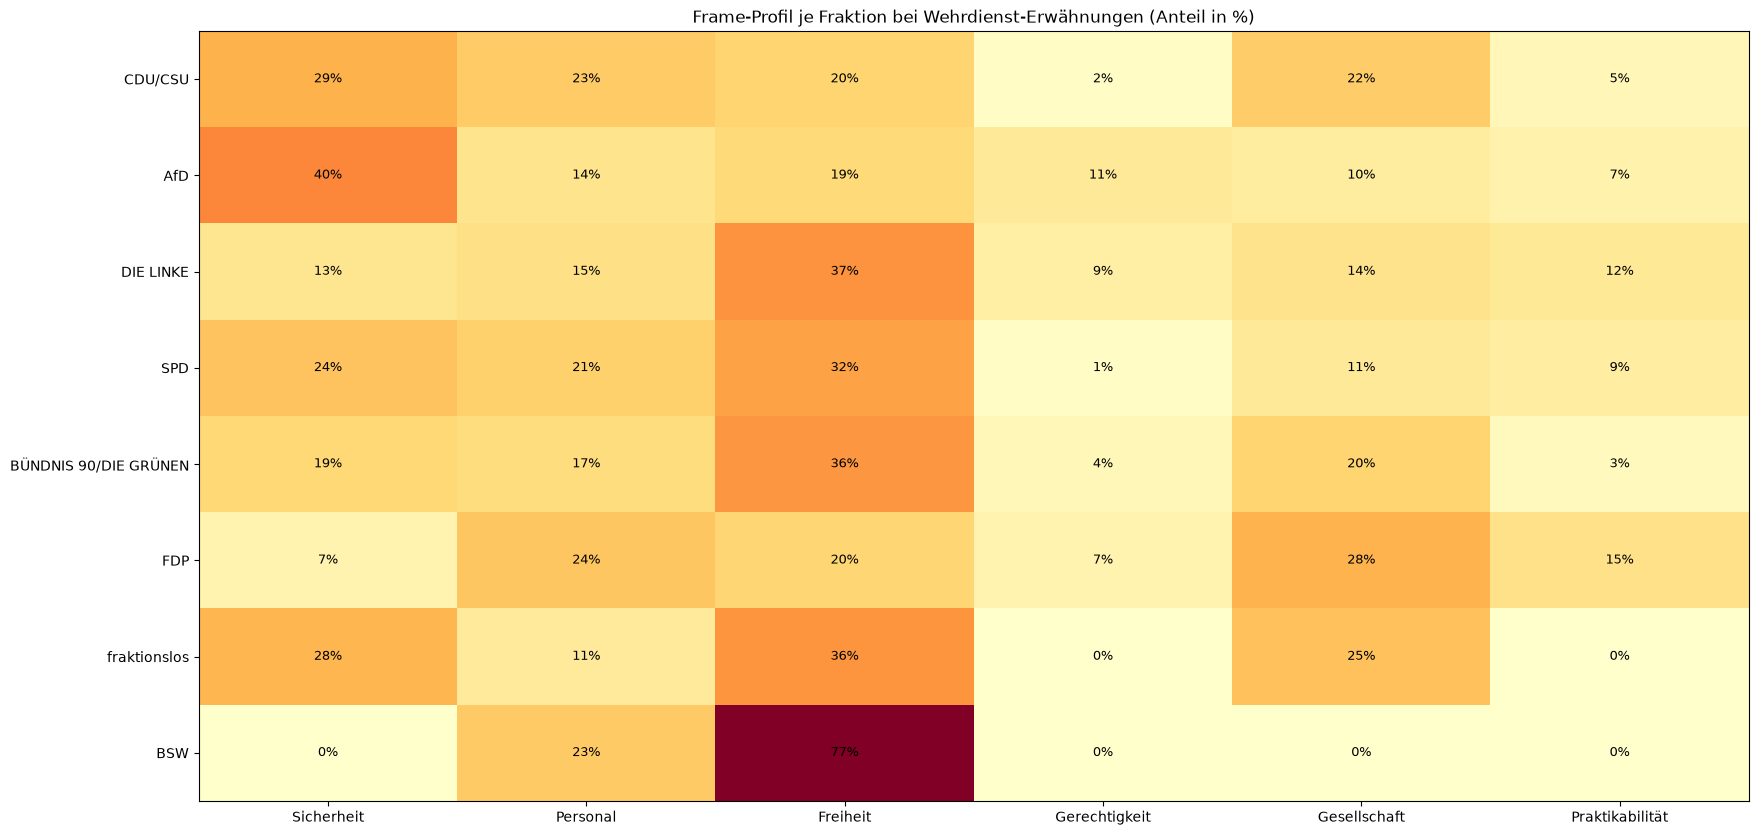

In [ ]:
# Block 9: Ich normalisiere die Frame-Häufigkeiten pro Fraktion auf Prozentanteile. Das ist wichtig, weil CDU/CSU und AfD mehr Reden zum Thema halten und
# absolute Zahlen würden also nur die Redemenge widerspiegeln, nicht den inhaltlichen Fokus

frame_by_fraction = relevant_speeches.groupby("fraction")[frame_columns].sum()

# Ich teile jede Zeile durch ihre Zeilensumme, damit jede Fraktion ein eigenes "Profil" bekommt, das sich zu 100% aufsummiert 
# So werden die Fraktionen untereinander vergleichbar, unabhängig von ihrer absoluten Redemenge

frame_profile_pct = frame_by_fraction.div(frame_by_fraction.sum(axis=1), axis=0) * 100

# Ich benenne die Spalten lesbarer, ohne das Präfix "frame_"

frame_profile_pct.columns = [c.replace("frame_", "") for c in frame_profile_pct.columns]

# Ich sortiere die Fraktionen nach Gesamtzahl der Wehrdienst-Erwähnungen, damit die größten/relevantesten Fraktionen oben in der Tabelle stehen


speech_order = relevant_speeches.groupby("fraction").size().sort_values(ascending=False).index

# Ich ordne die Zeilen von frame_profile_pct in eine bestimmte, vorher festgelegte Reihenfolge (speech_order) um
# reindex() sortiert den DataFrame anhand dieser Reihenfolge neu
frame_profile_pct = frame_profile_pct.reindex(speech_order)

print("Frame-Profil pro Fraktion (in % der Frame-Erwähnungen dieser Fraktion):")
print(frame_profile_pct.round(1))


# Ich visualisiere das Profil als Heatmap, weil das Muster (wer betont was) darin auf einen Blick sichtbar wird

fig, ax = plt.subplots(figsize=(20, 10))
# cmap (colormap) legt fest, welche Farbskala verwendet wird, um die Werte in der Heatmap darzustellen. "YlOrRd" (Yellow-Orange-Red) färbt niedrige Werte gelb und hohe Werte rot ein
im = ax.imshow(frame_profile_pct.values, cmap="YlOrRd", aspect="auto")

ax.set_xticks(range(len(frame_profile_pct.columns)))
ax.set_xticklabels(frame_profile_pct.columns)
ax.set_yticks(range(len(frame_profile_pct.index)))
ax.set_yticklabels(frame_profile_pct.index)

# Ich schreibe die Prozentwerte direkt in die Zellen, damit die Heatmap nicht nur ein grober Farbeindruck bleibt, sondern auch exakte Werte ablesbar sind

# Ich schreibe den Wert als Text in die Heatmap, an Position (j, i), weil bei Achsen x=Spalte und y=Zeile ist
# f"{value:.0f}%" rundet die Zahl auf eine ganze Zahl und hängt ein Prozentzeichen an
# ha/va="center" zentriert den Text horizontal und vertikal in der jeweiligen Zelle
        
for i in range(len(frame_profile_pct.index)):
    for j in range(len(frame_profile_pct.columns)):
        value = frame_profile_pct.values[i, j]
        ax.text(j, i, f"{value:.0f}%", ha="center", va="center", fontsize=9)

ax.set_title("Frame-Profil je Fraktion bei Wehrdienst-Erwähnungen (Anteil in %)")
plt.show()

In [10]:
# Block 10: Ich baue ein einfaches Ranking. Pro Abgeordneten/r, Partei, wie oft insgesamt Wehrdienst-Begriffe in ihren/seinen Reden vorkommen, absteigend sortiert

speaker_ranking = (
    relevant_speeches.groupby(["speaker_name", "fraction"])
    .agg(
        anzahl_reden_mit_erwaehnung=("keyword_hits", "count"),
        erwaehnungen_gesamt=("keyword_hits", "sum"),
    )
    .reset_index()
    .sort_values("erwaehnungen_gesamt", ascending=False)
)

print(f"Insgesamt {len(speaker_ranking)} Abgeordnete haben mindestens einmal Wehrdienst erwähnt.\n")
print(speaker_ranking.head(20).to_string(index=False))


Insgesamt 155 Abgeordnete haben mindestens einmal Wehrdienst erwähnt.

       speaker_name              fraction  anzahl_reden_mit_erwaehnung  erwaehnungen_gesamt
     Desiree Becker             DIE LINKE                            7                   38
   Rüdiger Lucassen                   AfD                           16                   38
       Thomas Erndl               CDU/CSU                           14                   37
  Diana Herbstreuth               CDU/CSU                            4                   18
   Dr. Rainer Kraft                   AfD                            1                   17
     Niklas Wagener BÜNDNIS 90/DIE GRÜNEN                            5                   17
     Siemtje Möller                   SPD                            4                   17
       Andreas Paul                   AfD                            2                   17
         Jens Spahn               CDU/CSU                            6                   15
    Thoma